# 01 - Data Understanding

**Objective:** Initial exploratory analysis, inspecting raw schemas, table shapes, and data distributions across IPL & T20I matches.

---
### supeRR Selector Pressure Analysis


In [3]:
# Setup and imports
import sys
from pathlib import Path

# Ensure src module is accessible
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.append(str(PROJECT_ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from superr_selector.data.loader import DataLoader

%matplotlib inline
print('Environment initialized successfully.')


Environment initialized successfully.


## 1. Load Datasets
## 1.1 Load Raw Datasets

Load all six original CSV files into Pandas DataFrames.

The raw datasets will remain unchanged throughout the analysis.


In [4]:

# Define the raw data directory
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load all six datasets
datasets = {
    "ball_by_ball": pd.read_csv(DATA_DIR / "ball_by_ball.csv"),
    "competition_team_player_mapping": pd.read_csv(
        DATA_DIR / "competition_team_player_mapping.csv"
    ),
    "competitions": pd.read_csv(DATA_DIR / "competitions.csv"),
    "matches": pd.read_csv(DATA_DIR / "matches.csv"),
    "playing_eleven": pd.read_csv(DATA_DIR / "playing_eleven.csv"),
    "teams": pd.read_csv(DATA_DIR / "teams.csv")
}

print("All datasets loaded successfully!")

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


All datasets loaded successfully!
ball_by_ball: (200999, 33)
competition_team_player_mapping: (6413, 6)
competitions: (141, 4)
matches: (883, 22)
playing_eleven: (28381, 9)
teams: (353, 3)


## 1.2 Dataset Structure Inspection

Inspect the dimensions and column names of every dataset.

In [5]:

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name.upper()}")
    print("=" * 70)

    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    print("\nColumn Names:")
    print(df.columns.tolist())



DATASET: BALL_BY_BALL
Rows: 200,999
Columns: 33

Column Names:
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time']

DATASET: COMPETITION_TEAM_PLAYER_MAPPING
Rows: 6,413
Columns: 6

Column Names:
['comp_id', 'comp_name', 'team_id', 'team_name', 'player_id', 'player_name']

DATASET: COMPETITIONS
Rows: 141
Columns: 4

Column Names:
['comp_id', 'comp_name', 'match_format', 'season']

DATASET: MATCHES
Rows: 883
Columns: 22

Column Names:
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_

## 1.3 Data Types Inspection

Inspect the data types of every column in all six datasets.

In [6]:

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name.upper()}")
    print("=" * 70)

    print(df.dtypes)



DATASET: BALL_BY_BALL
match_id                 int64
innings                  int64
overid                   int64
over_ball_num            int64
innings_ball_num         int64
batting_team_id          int64
bowling_team_id          int64
striker_id               int64
striker_name            object
non_striker_id           int64
non_striker_name        object
bowler_id                int64
bowler_name             object
batting_type            object
bowling_type            object
batting_order            int64
runs                     int64
is_four                   bool
is_six                    bool
is_wicket                 bool
dismissal_type_id      float64
dismissal_type          object
dismissed_player_id    float64
extras_type             object
extras1_runs             int64
extras_2_runs            int64
pace_or_spin            object
bowl_speed             float64
stroke                  object
delivery_style          object
over_or_around          object
on_or_off       

## 1.4 Sample Record Inspection

Inspect the first five records of every dataset to understand
the actual values stored in each column.

In [7]:

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name.upper()}")
    print("=" * 70)

    display(df.head(5))



DATASET: BALL_BY_BALL


,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,...,extras_type,extras1_runs,extras_2_runs,pace_or_spin,bowl_speed,stroke,delivery_style,over_or_around,on_or_off,delivery_ist_time
0,13511,1,1,1,1,22,28,1187,Jason Roy,6273,...,NaN,0,0,Pace,0.0,Cover Drive,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC
1,13511,1,1,2,2,22,28,1187,Jason Roy,6273,...,NaN,0,0,Pace,0.0,Flick,Inswing,Over,On-side,2022-01-23 00:00:00 UTC
2,13511,1,1,3,3,22,28,1187,Jason Roy,6273,...,NaN,0,0,Pace,0.0,Square Cut,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC
3,13511,1,1,4,4,22,28,1187,Jason Roy,6273,...,NaN,0,0,Pace,0.0,Backfoot defensive,Inswing,Over,On-side,2022-01-23 00:00:00 UTC
4,13511,1,1,5,5,22,28,1187,Jason Roy,6273,...,NaN,0,0,Pace,0.0,Pull shot,Seamed In,Over,On-side,2022-01-23 00:00:00 UTC



DATASET: COMPETITION_TEAM_PLAYER_MAPPING


,comp_id,comp_name,team_id,team_name,player_id,player_name
0,1331,England in West Indies T20I Series 2022,22,England,478,Eoin Morgan
1,1331,England in West Indies T20I Series 2022,22,England,479,Adil Rashid
2,1331,England in West Indies T20I Series 2022,22,England,722,Liam Dawson
3,1331,England in West Indies T20I Series 2022,22,England,786,Chris Jordan
4,1331,England in West Indies T20I Series 2022,22,England,1187,Jason Roy



DATASET: COMPETITIONS


,comp_id,comp_name,match_format,season
0,3395,South Africa in New Zealand T20I Series 2026,T20I,2026
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
2,3465,India in Zimbabwe T20I Series 2026,T20I,2026
3,3568,Bangladesh in Zimbabwe T20I Series 2026,T20I,2026
4,3482,Australia in Bangladesh T20I Series 2026,T20I,2026


... (2 outputs left out)


DATASET: PLAYING_ELEVEN


,match_id,team_id,player_id,batting_order,is_played,is_captain,is_wk,is_impact,is_impact_off
0,13511,22,1187,1.0,True,False,False,0,0
1,13511,22,6273,2.0,True,False,False,0,0
2,13511,22,1210,3.0,True,False,False,0,0
3,13511,22,1596,4.0,True,False,False,0,0
4,13511,22,478,5.0,True,False,False,0,0



DATASET: TEAMS


,comp_id,team_id,team_name
0,1331,22,England
1,1331,28,West Indies
2,1335,18,India
3,1335,28,West Indies
4,1345,20,Australia


## 1.5 Missing Value Analysis

Analyze missing values across all six datasets.

Calculate:
- Missing value count
- Missing value percentage
- Columns containing missing values

In [8]:

missing_summary = {}

for name, df in datasets.items():

    missing_count = df.isnull().sum()
    missing_percentage = (missing_count / len(df)) * 100

    summary = pd.DataFrame({
        "Missing_Count": missing_count,
        "Missing_Percentage": missing_percentage.round(2)
    })

    summary = summary[summary["Missing_Count"] > 0]
    summary = summary.sort_values(
        by="Missing_Percentage",
        ascending=False
    )

    missing_summary[name] = summary

    print("\n" + "=" * 70)
    print(f"MISSING VALUES: {name.upper()}")
    print("=" * 70)

    if summary.empty:
        print("No missing values found.")
    else:
        display(summary)



MISSING VALUES: BALL_BY_BALL


,Missing_Count,Missing_Percentage
dismissal_type_id,190118,94.59
dismissal_type,190118,94.59
dismissed_player_id,190107,94.58
extras_type,189167,94.11
stroke,6158,3.06
over_or_around,407,0.20
delivery_style,391,0.19



MISSING VALUES: COMPETITION_TEAM_PLAYER_MAPPING
No missing values found.

MISSING VALUES: COMPETITIONS
No missing values found.

MISSING VALUES: MATCHES


,Missing_Count,Missing_Percentage
revised_target,860,97.40
first_inn_revised_overs,858,97.17
second_inn_revised_overs,858,97.17
away_team_captain_id,45,5.10
home_team_captain_id,44,4.98
win_team_id,41,4.64
toss_opted,15,1.70
toss_win_team_id,15,1.70



MISSING VALUES: PLAYING_ELEVEN


,Missing_Count,Missing_Percentage
batting_order,8678,30.58
is_captain,8667,30.54
is_wk,8667,30.54



MISSING VALUES: TEAMS
No missing values found.


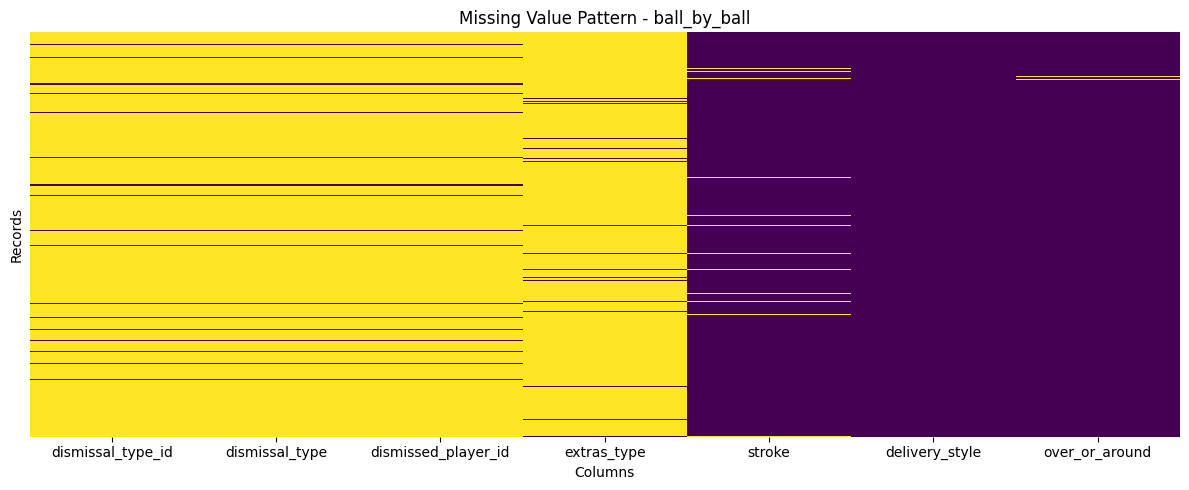

competition_team_player_mapping: No missing values.
competitions: No missing values.


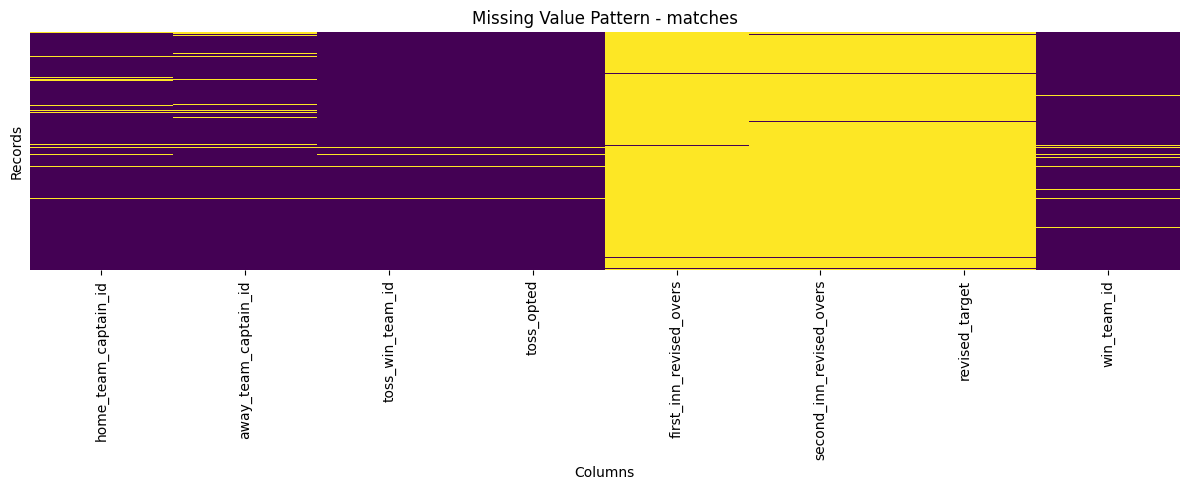

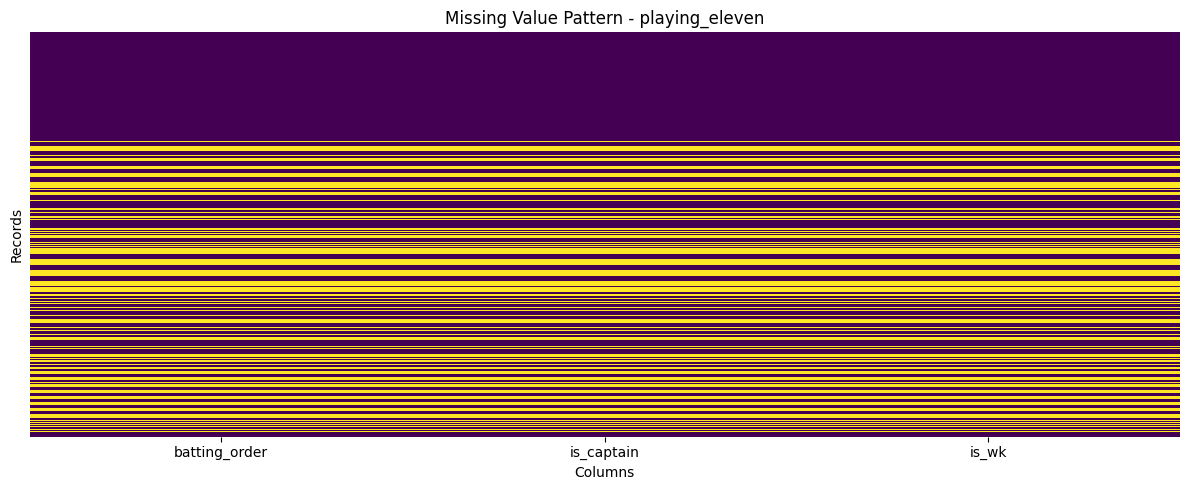

teams: No missing values.


In [9]:

for name, df in datasets.items():

    missing_columns = df.columns[df.isnull().any()].tolist()

    if len(missing_columns) == 0:
        print(f"{name}: No missing values.")
        continue

    plt.figure(figsize=(12, 5))

    sns.heatmap(
        df[missing_columns].isnull(),
        cbar=False,
        yticklabels=False,
        cmap="viridis"
    )

    plt.title(f"Missing Value Pattern - {name}")
    plt.xlabel("Columns")
    plt.ylabel("Records")
    plt.tight_layout()
    plt.show()


## 1.6 Duplicate Record Analysis

Identify exact duplicate rows in all six datasets.

In [10]:

duplicate_summary = {}

for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()

    duplicate_summary[name] = {
        "Total_Rows": len(df),
        "Duplicate_Rows": duplicate_count,
        "Duplicate_Percentage": round(
            duplicate_count / len(df) * 100, 2
        )
    }

duplicate_df = pd.DataFrame(duplicate_summary).T

display(duplicate_df)


,Total_Rows,Duplicate_Rows,Duplicate_Percentage
ball_by_ball,200999.0,0.0,0.0
competition_team_player_mapping,6413.0,0.0,0.0
competitions,141.0,0.0,0.0
matches,883.0,0.0,0.0
playing_eleven,28381.0,0.0,0.0
teams,353.0,0.0,0.0


In [11]:

ball_df = datasets["ball_by_ball"]

# Compare wicket indicator with dismissal information
wicket_missing_analysis = (
    ball_df.groupby("is_wicket")
    .agg(
        total_deliveries=("match_id", "size"),
        missing_dismissal_type=("dismissal_type", lambda x: x.isna().sum()),
        missing_dismissed_player=("dismissed_player_id", lambda x: x.isna().sum())
    )
)

display(wicket_missing_analysis)


,total_deliveries,missing_dismissal_type,missing_dismissed_player
is_wicket,,,
False,190118,190118,190106
True,10881,0,1


In [12]:
# Create a temporary analysis column; original data remains unchanged
extras_analysis = ball_df.assign(
    total_extras=ball_df["extras1_runs"] + ball_df["extras_2_runs"]
)

extras_analysis["has_extras"] = extras_analysis["total_extras"] > 0

extras_summary = (
    extras_analysis.groupby("has_extras")
    .agg(
        deliveries=("match_id", "size"),
        missing_extras_type=("extras_type", lambda x: x.isna().sum())
    )
)

display(extras_summary)

,deliveries,missing_extras_type
has_extras,,
False,189166,189165
True,11833,2


In [13]:
playing_df = datasets["playing_eleven"]

playing_missing_analysis = (
    playing_df.groupby("is_played", dropna=False)
    .agg(
        total_records=("player_id", "size"),
        missing_batting_order=("batting_order", lambda x: x.isna().sum()),
        missing_captain=("is_captain", lambda x: x.isna().sum()),
        missing_wicketkeeper=("is_wk", lambda x: x.isna().sum())
    )
)

display(playing_missing_analysis)

,total_records,missing_batting_order,missing_captain,missing_wicketkeeper
is_played,,,,
False,8667,8667,8667,8667
True,19714,11,0,0


In [14]:
matches_df = datasets["matches"]

missing_winner_matches = matches_df[
    matches_df["win_team_id"].isna()
]

display(
    missing_winner_matches[
        ["match_id", "match_date", "stage", "result", "win_team_id"]
    ]
)

print("Total matches without a winner:", len(missing_winner_matches))

,match_id,match_date,stage,result,win_team_id
94,15410,2022-06-19,League,Match Abandoned,NaN
95,15546,2022-07-02,League,No Result,NaN
177,17765,2022-10-14,League,No Result,NaN
179,18532,2022-11-22,League,Match Tied,NaN
234,20226,2023-05-03,League,Match Abandoned,NaN
281,21406,2023-04-20,League,Match Abandoned,NaN
315,28333,2023-12-29,Others,No Result,NaN
396,31281,2024-05-13,League,Match Abandoned,NaN
399,31284,2024-05-16,League,Match Abandoned,NaN
403,31288,2024-05-19,League,Match Abandoned,NaN


Total matches without a winner: 41


In [15]:

ball_df = datasets["ball_by_ball"]

print("Wicket consistency checks")

print(
    "Wickets without dismissal type:",
    ball_df.loc[
        ball_df["is_wicket"] & ball_df["dismissal_type"].isna()
    ].shape[0]
)

print(
    "Non-wickets with dismissal type:",
    ball_df.loc[
        ~ball_df["is_wicket"] & ball_df["dismissal_type"].notna()
    ].shape[0]
)

print(
    "Wickets without dismissed player ID:",
    ball_df.loc[
        ball_df["is_wicket"] & ball_df["dismissed_player_id"].isna()
    ].shape[0]
)


Wicket consistency checks
Wickets without dismissal type: 0
Non-wickets with dismissal type: 0
Wickets without dismissed player ID: 1


In [16]:

print("Boundary consistency checks")

print(
    "is_four records:",
    ball_df["is_four"].sum()
)

print(
    "is_six records:",
    ball_df["is_six"].sum()
)

print(
    "Both four and six:",
    (ball_df["is_four"] & ball_df["is_six"]).sum()
)

print(
    "Four records where runs != 4:",
    (ball_df["is_four"] & (ball_df["runs"] != 4)).sum()
)

print(
    "Six records where runs != 6:",
    (ball_df["is_six"] & (ball_df["runs"] != 6)).sum()
)


Boundary consistency checks
is_four records: 23283
is_six records: 12811
Both four and six: 0
Four records where runs != 4: 0
Six records where runs != 6: 0


In [17]:

print("Runs and extras inspection")

print("\nRuns distribution:")
display(ball_df["runs"].value_counts().sort_index())

print("\nExtras1 distribution:")
display(ball_df["extras1_runs"].value_counts().sort_index())

print("\nExtras2 distribution:")
display(ball_df["extras_2_runs"].value_counts().sort_index())

print("\nExtras categories:")
display(ball_df["extras_type"].value_counts(dropna=False))


Runs and extras inspection

Runs distribution:


runs
0    79387
1    72267
2    12547
3      656
4    23303
5       25
6    12814
Name: count, dtype: int64


Extras1 distribution:


extras1_runs
0    189167
1     10672
2       458
3        47
4       381
5       274
Name: count, dtype: int64


Extras2 distribution:


extras_2_runs
0    200963
1        20
4        16
Name: count, dtype: int64


Extras categories:


extras_type
NaN         189167
wide          7714
legbyes       2748
Overstep       576
byes           529
other          264
Penalty          1
Name: count, dtype: int64

In [18]:
# 1. Wicket without dismissed player ID
missing_wicket_player = ball_df[
    ball_df["is_wicket"] &
    ball_df["dismissed_player_id"].isna()
]

print("Wicket without dismissed player ID:")
display(
    missing_wicket_player[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "striker_name",
            "bowler_name",
            "runs",
            "dismissal_type",
            "dismissed_player_id"
        ]
    ]
)

# 2. Delivery with extras but missing extras category
ball_df["total_extras"] = (
    ball_df["extras1_runs"] + ball_df["extras_2_runs"]
)

missing_extras_category = ball_df[
    (ball_df["total_extras"] > 0) &
    ball_df["extras_type"].isna()
]

print("Delivery with extras but missing extras category:")
display(
    missing_extras_category[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "striker_name",
            "bowler_name",
            "runs",
            "extras1_runs",
            "extras_2_runs",
            "total_extras",
            "extras_type"
        ]
    ]
)

Wicket without dismissed player ID:


,match_id,innings,overid,over_ball_num,striker_name,bowler_name,runs,dismissal_type,dismissed_player_id
127899,40709,2,19,5,Hardik Pandya,Shardul Thakur,1,Retire Out,NaN


Delivery with extras but missing extras category:


,match_id,innings,overid,over_ball_num,striker_name,bowler_name,runs,extras1_runs,extras_2_runs,total_extras,extras_type
36854,17555,1,5,4,Dawid Malan,Haris Rauf,0,0,1,1,NaN
107489,36097,2,8,6,Rassie van der Dussen,Romario Shepherd,0,1,0,1,NaN


In [19]:
# Load the required datasets
ball_df = datasets["ball_by_ball"]
matches_df = datasets["matches"]
mapping_df = datasets["competition_team_player_mapping"]
competitions_df = datasets["competitions"]

# 1. Match IDs
ball_match_ids = set(ball_df["match_id"].unique())
known_match_ids = set(matches_df["match_id"].unique())

print("MATCH ID VALIDATION")
print("Unique matches in ball-by-ball:", len(ball_match_ids))
print("Unique matches in matches.csv:", len(known_match_ids))
print("Ball-by-ball match IDs not found in matches.csv:",
      len(ball_match_ids - known_match_ids))

# 2. Player IDs
ball_player_ids = set(
    pd.concat([
        ball_df["striker_id"],
        ball_df["non_striker_id"],
        ball_df["bowler_id"]
    ]).dropna().unique()
)

known_player_ids = set(mapping_df["player_id"].unique())

print("\nPLAYER ID VALIDATION")
print("Unique player IDs in ball-by-ball:", len(ball_player_ids))
print("Unique player IDs in mapping:", len(known_player_ids))
print("Ball-by-ball player IDs not found in mapping:",
      len(ball_player_ids - known_player_ids))

# 3. Competition IDs
match_comp_ids = set(matches_df["comp_id"].dropna().unique())
known_comp_ids = set(competitions_df["comp_id"].unique())

print("\nCOMPETITION ID VALIDATION")
print("Match competition IDs:", len(match_comp_ids))
print("Known competition IDs:", len(known_comp_ids))
print("Match competition IDs not found in competitions.csv:",
      len(match_comp_ids - known_comp_ids))

MATCH ID VALIDATION
Unique matches in ball-by-ball: 867
Unique matches in matches.csv: 883
Ball-by-ball match IDs not found in matches.csv: 0

PLAYER ID VALIDATION
Unique player IDs in ball-by-ball: 959
Unique player IDs in mapping: 1217
Ball-by-ball player IDs not found in mapping: 0

COMPETITION ID VALIDATION
Match competition IDs: 138
Known competition IDs: 141
Match competition IDs not found in competitions.csv: 0


In [20]:
# 1. Matches without ball-by-ball records
matches_without_ball_data = matches_df[
    ~matches_df["match_id"].isin(ball_match_ids)
]

print("Matches without ball-by-ball data:")
print("Total:", len(matches_without_ball_data))

display(
    matches_without_ball_data[
        [
            "match_id",
            "comp_id",
            "match_date",
            "stage",
            "home_team",
            "away_team",
            "result"
        ]
    ].head(20)
)


# 2. Players in mapping but absent from ball-by-ball data
players_without_ball_data = mapping_df[
    ~mapping_df["player_id"].isin(ball_player_ids)
]

print("\nPlayers without ball-by-ball records:")
print("Total unique player IDs:",
      players_without_ball_data["player_id"].nunique())

display(
    players_without_ball_data[
        ["player_id", "player_name", "comp_name", "team_name"]
    ].head(20)
)


# 3. Competitions without matches
competitions_without_matches = competitions_df[
    ~competitions_df["comp_id"].isin(match_comp_ids)
]

print("\nCompetitions without matches:")
print("Total:", len(competitions_without_matches))

display(competitions_without_matches)

Matches without ball-by-ball data:
Total: 16


,match_id,comp_id,match_date,stage,home_team,away_team,result
396,31281,2193,2024-05-13,League,Gujarat Titans,Kolkata Knight Riders,Match Abandoned
399,31284,2193,2024-05-16,League,Sunrisers Hyderabad,Gujarat Titans,Match Abandoned
403,31288,2193,2024-05-19,League,Rajasthan Royals,Kolkata Knight Riders,Match Abandoned
425,32610,2354,2024-05-22,Others,England,Pakistan,Match Abandoned
427,32612,2354,2024-05-28,Others,England,Pakistan,Match Abandoned
447,32622,2398,2024-05-20,Others,Ireland,Scotland,Match Abandoned
453,38797,2442,2024-12-14,League,South Africa,Pakistan,Match Abandoned
481,36564,2548,2024-09-15,League,England,Australia,Match Abandoned
498,36210,2628,2025-09-14,League,England,South Africa,Match Abandoned
593,40761,2725,2025-05-17,League,Royal Challengers Bengaluru,Kolkata Knight Riders,Match Abandoned



Players without ball-by-ball records:
Total unique player IDs: 258


,player_id,player_name,comp_name,team_name
71,224,Moises Henriques,Sri Lanka in Australia T20I Series 2022,Australia
105,22515,Shiran Fernando,Sri Lanka in Australia T20I Series 2022,Sri Lanka
108,35,Nathan Bracken,IPL 2022,Chennai Super Kings
122,5668,Hari Nishaanth,IPL 2022,Chennai Super Kings
124,6408,Subhranshu Senapati,IPL 2022,Chennai Super Kings
132,20694,Bhagath Varma,IPL 2022,Chennai Super Kings
149,6492,Aryan Juyal,IPL 2022,Mumbai Indians
158,20029,Rahul Buddhi,IPL 2022,Mumbai Indians
173,4080,KC Cariappa,IPL 2022,Rajasthan Royals
178,6036,Tejas Baroka,IPL 2022,Rajasthan Royals



Competitions without matches:
Total: 3


,comp_id,comp_name,match_format,season
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
11,3473,United Arab Emirates in Nepal T20I Series 2026,T20I,2026
118,2940,India in Bangladesh T20I Series 2025,T20I,2025


In [21]:
# Competition format distribution

print("Competition formats:")
display(
    competitions_df["match_format"]
    .value_counts(dropna=False)
    .to_frame("competition_count")
)

# Season distribution

print("\nCompetition seasons:")
display(
    competitions_df["season"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("competition_count")
)

# Format and season combination

print("\nCompetition format by season:")
display(
    pd.crosstab(
        competitions_df["season"],
        competitions_df["match_format"],
        margins=True
    )
)

Competition formats:


,competition_count
match_format,
T20I,134
T20,7



Competition seasons:


,competition_count
season,
2022,25
2022/23,3
2023,20
2023/24,1
2024,33
2024/25,1
2025,33
2026,25



Competition format by season:


match_format,T20,T20I,All
season,,,
2022,1,24,25
2022/23,0,3,3
2023,1,19,20
2023/24,0,1,1
2024,2,31,33
2024/25,0,1,1
2025,2,31,33
2026,1,24,25
All,7,134,141


In [22]:
t20_competitions = competitions_df[
    competitions_df["match_format"] == "T20"
].sort_values("season")

display(t20_competitions)

,comp_id,comp_name,match_format,season
12,1358,IPL 2022,T20,2022
13,1715,IPL 2023,T20,2023
14,2670,Mens T20 Emerging Teams Asia Cup 2024,T20,2024
15,2193,IPL 2024,T20,2024
16,2725,IPL 2025,T20,2025
17,3289,Asia Cup Rising Stars 2025,T20,2025
18,3298,IPL 2026,T20,2026


In [23]:
t20_comp_ids = t20_competitions["comp_id"]

t20_matches = matches_df[
    matches_df["comp_id"].isin(t20_comp_ids)
]

print("Matches belonging to T20 competitions:",
      len(t20_matches))

display(
    t20_matches.groupby("comp_id").agg(
        competition_matches=("match_id", "nunique"),
        first_match=("match_date", "min"),
        last_match=("match_date", "max")
    ).reset_index().merge(
        t20_competitions[["comp_id", "comp_name", "season"]],
        on="comp_id",
        how="left"
    )
)

Matches belonging to T20 competitions: 401


,comp_id,competition_matches,first_match,last_match,comp_name,season
0,1358,74,2022-03-26,2022-05-29,IPL 2022,2022
1,1715,74,2023-03-31,2023-05-29,IPL 2023,2023
2,2193,74,2024-03-22,2024-05-26,IPL 2024,2024
3,2670,15,2024-10-18,2024-10-27,Mens T20 Emerging Teams Asia Cup 2024,2024
4,2725,75,2025-03-22,2025-06-03,IPL 2025,2025
5,3289,15,2025-11-14,2025-11-23,Asia Cup Rising Stars 2025,2025
6,3298,74,2026-03-28,2026-05-31,IPL 2026,2026


In [24]:
# Identify IPL 2025 competition ID
ipl_2025_comp_id = competitions_df.loc[
    competitions_df["comp_name"] == "IPL 2025",
    "comp_id"
].iloc[0]

# Extract IPL 2025 matches
ipl_2025_matches = matches_df[
    matches_df["comp_id"] == ipl_2025_comp_id
].sort_values("match_date")

print("Total IPL 2025 match records:", len(ipl_2025_matches))

display(
    ipl_2025_matches[
        [
            "match_id",
            "match_number",
            "match_date",
            "stage",
            "home_team",
            "away_team",
            "result",
            "win_team_id"
        ]
    ]
)

Total IPL 2025 match records: 75


,match_id,match_number,match_date,stage,home_team,away_team,result,win_team_id
526,40694,1,2025-03-22,League,Kolkata Knight Riders,Royal Challengers Bengaluru,Royal Challengers Bengaluru Won by 7 wickets,5.0
527,40695,2,2025-03-23,League,Sunrisers Hyderabad,Rajasthan Royals,Sunrisers Hyderabad Won by 44 runs,242.0
528,40696,3,2025-03-23,League,Chennai Super Kings,Mumbai Indians,Chennai Super Kings Won by 4 wickets,1.0
529,40697,4,2025-03-24,League,Delhi Capitals,Lucknow Super Giants,Delhi Capitals Won by 1 wickets,7.0
530,40698,5,2025-03-25,League,Gujarat Titans,Punjab Kings,Punjab Kings Won by 11 runs,4.0
...,...,...,...,...,...,...,...,...
584,40752,71,2025-05-27,League,Lucknow Super Giants,Royal Challengers Bengaluru,Royal Challengers Bengaluru Won by 6 wickets,5.0
596,40764,72,2025-05-29,Qualifier,Punjab Kings,Royal Challengers Bengaluru,Royal Challengers Bengaluru Won by 8 wickets,5.0
597,40765,73,2025-05-30,Eliminator,Gujarat Titans,Mumbai Indians,Mumbai Indians Won by 20 runs,2.0
598,40766,74,2025-06-01,Qualifier,Punjab Kings,Mumbai Indians,Punjab Kings Won by 5 wickets,4.0


In [25]:
# 1. Check duplicate match numbers
print("Duplicate match numbers:")
display(
    ipl_2025_matches[
        ipl_2025_matches.duplicated(
            subset=["match_number"],
            keep=False
        )
    ][
        ["match_id", "match_number", "match_date",
         "home_team", "away_team", "result"]
    ].sort_values("match_number")
)

# 2. Check match number coverage
expected_numbers = set(range(1, 75 + 1))
actual_numbers = set(ipl_2025_matches["match_number"].dropna())

print("\nMatch number validation")
print("Unique match numbers:", len(actual_numbers))
print("Missing match numbers:", sorted(expected_numbers - actual_numbers))
print("Numbers outside 1-75:", sorted(actual_numbers - expected_numbers))

# 3. Check results and stages
print("\nMatch results:")
display(ipl_2025_matches["result"].value_counts(dropna=False))

print("\nMatch stages:")
display(ipl_2025_matches["stage"].value_counts(dropna=False))

# 4. Check ball-by-ball coverage
ipl_2025_match_ids = set(ipl_2025_matches["match_id"])
ball_match_ids = set(ball_df["match_id"].unique())

print("\nBall-by-ball coverage")
print("Matches with ball-by-ball data:",
      len(ipl_2025_match_ids & ball_match_ids))
print("Matches without ball-by-ball data:",
      len(ipl_2025_match_ids - ball_match_ids))

Duplicate match numbers:


,match_id,match_number,match_date,home_team,away_team,result



Match number validation
Unique match numbers: 75
Missing match numbers: []
Numbers outside 1-75: []

Match results:


result
No Result                                       3
Kolkata Knight Riders Won by 8 wickets          2
Royal Challengers Bengaluru Won by 7 wickets    2
Royal Challengers Bengaluru Won by 6 wickets    2
Delhi Capitals Won by 6 wickets                 2
                                               ..
Chennai Super Kings Won by 83 runs              1
Punjab Kings Won by 7 wickets                   1
Royal Challengers Bengaluru Won by 8 wickets    1
Mumbai Indians Won by 20 runs                   1
Royal Challengers Bengaluru Won by 6 runs       1
Name: count, Length: 67, dtype: int64


Match stages:


stage
League        71
Qualifier      2
Eliminator     1
Final          1
Name: count, dtype: int64


Ball-by-ball coverage
Matches with ball-by-ball data: 74
Matches without ball-by-ball data: 1


In [26]:
# Find IPL 2025 match without ball-by-ball data

ipl_2025_missing = ipl_2025_matches[
    ~ipl_2025_matches["match_id"].isin(ball_df["match_id"])
]

display(
    ipl_2025_missing[
        [
            "match_id",
            "match_number",
            "match_date",
            "stage",
            "home_team",
            "away_team",
            "result",
            "win_team_id"
        ]
    ]
)

,match_id,match_number,match_date,stage,home_team,away_team,result,win_team_id
593,40761,59,2025-05-17,League,Royal Challengers Bengaluru,Kolkata Knight Riders,Match Abandoned,NaN
